In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json

In [2]:
train = pd.read_csv("../data/fraudTrain.csv", parse_dates=["trans_date_trans_time"])
test  = pd.read_csv("../data/fraudTest.csv",  parse_dates=["trans_date_trans_time"])
train["split"] = "train"
test["split"] = "test"

df = pd.concat([train, test], ignore_index=True).drop(columns=["Unnamed: 0"])
df = df.sort_values(["cc_num", "trans_date_trans_time"]).reset_index(drop=True)
print(df.shape)

(1852394, 23)


In [3]:
df.head()

,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,...,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud,split
0,2019-01-01 12:47:15,60416207185,"fraud_Jones, Sawayn and Romaguera",misc_net,7.27,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,...,-108.8964,1645,Information systems manager,1986-02-17,98e3dcf98101146a577f85a34e58feec,1325422035,43.974711,-109.741904,0,train
1,2019-01-02 08:44:57,60416207185,fraud_Berge LLC,gas_transport,52.94,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,...,-108.8964,1645,Information systems manager,1986-02-17,498120fc45d277f7c88e3dba79c33865,1325493897,42.018766,-109.044172,0,train
2,2019-01-02 08:47:36,60416207185,fraud_Luettgen PLC,gas_transport,82.08,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,...,-108.8964,1645,Information systems manager,1986-02-17,95f514bb993151347c7acdf8505c3d62,1325494056,42.961335,-109.157564,0,train
3,2019-01-02 12:38:14,60416207185,fraud_Daugherty LLC,kids_pets,34.79,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,...,-108.8964,1645,Information systems manager,1986-02-17,4f0c1a14e0aa7eb56a490780ef9268c5,1325507894,42.228227,-108.747683,0,train
4,2019-01-02 13:10:46,60416207185,fraud_Beier and Sons,home,27.18,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,...,-108.8964,1645,Information systems manager,1986-02-17,3b2ebd3af508afba959640893e1e82bc,1325509846,43.321745,-108.091143,0,train


In [5]:
#finding time 
t = df["trans_date_trans_time"]
df["hour"] = t.dt.hour
df["is_night"] = df["hour"].isin([22, 23, 0, 1, 2, 3]).astype(int)
df["day_of_week"] = t.dt.dayofweek          # 0 = Monday
df["age"] = (t - pd.to_datetime(df["dob"])).dt.days // 365

In [6]:
#distance between merchant and customers address
lat1, lon1 = np.radians(df["lat"]), np.radians(df["long"])
lat2, lon2 = np.radians(df["merch_lat"]), np.radians(df["merch_long"])
a = np.sin((lat2 - lat1) / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2)**2 #haversie formula
df["distance_km"] = 6371 * 2 * np.arcsin(np.sqrt(a))

In [7]:
#comparing amount with users earlier amounts only
g = df.groupby("cc_num")["amt"]
prev_total = g.cumsum() - df["amt"]          # total of all EARLIER payments
prev_count = g.cumcount()                    # number of EARLIER payments
df["avg_amt_before"] = prev_total / prev_count.replace(0, np.nan)
df["amt_ratio"] = (df["amt"] / df["avg_amt_before"]).fillna(1)   # first payment: treat as normal

In [8]:
# payments by this card in the previous 24 hours (not counting this one)
df["txn_24h"] = (
    df.set_index("trans_date_trans_time")
      .groupby("cc_num")["amt"]
      .rolling("24h").count()
      .to_numpy() - 1
)

# hours since this card's previous payment (capped at 1 week)
df["hours_since_last"] = (
    df.groupby("cc_num")["trans_date_trans_time"].diff().dt.total_seconds() / 3600
).fillna(168).clip(upper=168)

In [9]:
categories = sorted(df["category"].unique())
cat_map = {c: i for i, c in enumerate(categories)}
df["category_code"] = df["category"].map(cat_map)

with open("../models/category_map.json", "w") as f:
    json.dump(cat_map, f, indent=2)

In [10]:
features = ["amt", "amt_ratio", "hour", "is_night", "day_of_week", "age",
            "distance_km", "txn_24h", "hours_since_last", "city_pop", "category_code"]

df.groupby("is_fraud")[["amt", "amt_ratio", "is_night", "txn_24h", "hours_since_last", "distance_km", "age"]].mean().T

is_fraud,0,1
amt,67.651278,530.661412
amt_ratio,0.981553,7.063099
is_night,0.231639,0.846441
txn_24h,4.109675,4.304528
hours_since_last,8.681405,7.385004
distance_km,76.110969,76.256233
age,45.783466,48.361206


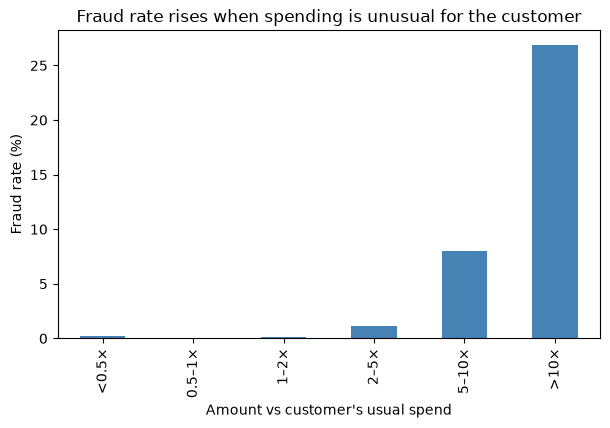

In [11]:
bins = [0, 0.5, 1, 2, 5, 10, np.inf]
labels = ["<0.5×", "0.5–1×", "1–2×", "2–5×", "5–10×", ">10×"]
df["ratio_band"] = pd.cut(df["amt_ratio"], bins=bins, labels=labels)

(df.groupby("ratio_band", observed=True)["is_fraud"].mean() * 100).plot(kind="bar", color="steelblue", figsize=(7, 4))
plt.ylabel("Fraud rate (%)"); plt.xlabel("Amount vs customer's usual spend")
plt.title("Fraud rate rises when spending is unusual for the customer")
plt.savefig("../images/fraud_by_amt_ratio.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
keep = features + ["is_fraud", "split", "trans_date_trans_time"]
df[keep].to_pickle("../data/features.pkl")
print("Saved:", df[keep].shape)

Saved: (1852394, 14)
